<div dir="rtl" style="text-align: right;">

# چالش آماری علم داده ترم 3 (شماره 1)

- نام: Kiarash Akbari
- مجموعه: آزمایشگاه فناوری های مالی داتین
- تاریخ: 15 مهر 1405
- فایل داده: bank_midterm.csv با 400 مشتری کارت بانکی
- متغیرهای پاسخ: monthly_spend برای رگرسیون خطی و default برای لجستیک

</div>

<div dir="rtl" style="text-align: right;">

### 1. تنظیمات اولیه

</div>

In [757]:
import os
from pathlib import Path
import numpy as np
import pandas as pd

pd.set_option('display.width', 120)
pd.set_option('display.max_columns', 20)
np.random.seed(42)

def find_data():
    p = Path(os.getcwd()).resolve()
    for f in [p, *p.parents]:
        for q in [f / 'bank_midterm.csv', f / 'term-3' / 'datasets' / 'bank_midterm.csv']:
            if q.exists():
                return q
    raise FileNotFoundError('bank_midterm.csv not found')

DATA_PATH = find_data()
OUT_DIR = Path('data')
OUT_DIR.mkdir(exist_ok=True)
print(DATA_PATH.exists())

True


<div dir="rtl" style="text-align: right;">

### 2. خواندن داده و نگاه کلی

</div>

In [758]:
raw = pd.read_csv(DATA_PATH)
df = raw.copy()
print(df.shape)
df.head()

(400, 14)


,id,age,income,tenure_months,n_products,savings,investments,total_assets,region,debt_ratio,late_payments,legal_case,monthly_spend,default
0,1,41,34.5,22,5,216.7,22.6,239.3,Tehran,0.179,1,1,7.77,1
1,2,59,26.2,30,6,158.4,36.4,194.8,Tehran,0.323,2,0,6.44,0
2,3,56,17.5,60,2,107.9,22.2,130.1,Metro,0.327,1,0,3.97,0
3,4,58,17.4,102,3,104.2,34.4,138.6,Other,0.422,0,0,1.48,0
4,5,64,27.2,35,1,180.4,20.4,200.8,Tehran,0.661,0,0,4.17,0


In [759]:
pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing': df.isna().sum() , 'unique': df.nunique()})

,dtype,missing,unique
id,int64,0,400
age,int64,0,44
income,float64,0,271
tenure_months,int64,0,109
n_products,int64,0,8
savings,float64,0,378
investments,float64,0,341
total_assets,float64,0,376
region,str,0,3
debt_ratio,float64,0,288


<div dir="rtl" style="text-align: right;">

### 3. چک کیفیت داده

</div>

In [760]:
chk = {
    'missing': int(df.isna().sum().sum()),
    'dup rows': int(df.drop(columns='id').duplicated().sum()),
    'id unique': bool(df['id'].is_unique),
    'income<=0': int((df['income'] <= 0).sum()),
    'spend<=0': int((df['monthly_spend'] <= 0).sum()),
    'tenure<=0': int((df['tenure_months'] <= 0).sum()),
    'debt_ratio not in 0-1': int((~df['debt_ratio'].between(0, 1)).sum()),
    'age not in 18-100': int((~df['age'].between(18, 100)).sum()),
    'late_payments not in 0-12': int((~df['late_payments'].between(0, 12)).sum()),
    'legal_case not 0/1': int((~df['legal_case'].isin([0, 1])).sum()),
    'default not 0/1': int((~df['default'].isin([0, 1])).sum()),
}
pd.Series(chk, name='n').to_frame()

,n
missing,0
dup rows,0
id unique,True
income<=0,0
spend<=0,0
tenure<=0,0
debt_ratio not in 0-1,0
age not in 18-100,0
late_payments not in 0-12,0
legal_case not 0/1,0


In [761]:
print(df['region'].value_counts())
print('extra spaces:', (df['region'] != df['region'].str.strip()).sum())

region
Tehran    162
Other     121
Metro     117
Name: count, dtype: int64
extra spaces: 0


<div dir="rtl" style="text-align: right;">

مقدار گمشده، سطر تکراری یا برچسب اشتباه توی region نداریم و داده از نظر ثبت تمیز است. دو چیز دیگر را هم چک می کنم که ممکن است توی مدل مشکل بسازند.

</div>

<div dir="rtl" style="text-align: right;">

### 4. رابطه ستون های مالی

</div>

In [762]:
gap = (df['total_assets'] - df['savings'] - df['investments']).round(2)
print('max gap:', gap.abs().max())
print('broken rows:', (gap.abs() > 0.05).sum())
print('corr income-savings:', round(df['income'].corr(df['savings']), 4))
r = df['savings'] / df['income']
print('savings/income mean, std:', round(r.mean(), 2), round(r.std(), 2))

max gap: 0.0
broken rows: 0
corr income-savings: 0.9952
savings/income mean, std: 5.98 0.41


<div dir="rtl" style="text-align: right;">

total_assets توی هر 400 سطر دقیقا برابر جمع savings و investments است، پس اطلاعات جدیدی ندارد. savings و income هم تقریبا روی یک خط راست اند. این ها خطای داده نیستند ولی روی مدل اثر دارند. توی سوال 1 باید با رتبه ماتریس و VIF نشانشان بدهم پس الان حذفشان نمی کنم.

</div>

<div dir="rtl" style="text-align: right;">

### 5. داده های دور از بقیه

</div>

In [763]:
rows = []
for c in ['income', 'savings', 'investments', 'tenure_months', 'monthly_spend']:
    q1, q3 = df[c].quantile([0.25, 0.75])
    k = 3 * (q3 - q1)
    far = df[(df[c] > q3 + k) | (df[c] < q1 - k)]
    rows.append({'col': c, 'n_far': len(far), 'max': df[c].max(), 'median': df[c].median()})
pd.DataFrame(rows)

,col,n_far,max,median
0,income,7,190.00,31.500
1,savings,7,1122.30,189.750
2,investments,8,332.50,43.850
3,tenure_months,0,128.00,35.000
4,monthly_spend,17,57.88,4.845


In [764]:
cols = ['id', 'income', 'savings', 'investments', 'monthly_spend']
df.nlargest(5, 'income')[cols]

,id,income,savings,investments,monthly_spend
310,311,190.0,1122.3,15.3,3.50
367,368,170.0,1002.1,47.8,2.50
31,32,160.0,958.9,7.5,39.45
151,152,150.0,917.5,85.7,3.00
83,84,109.0,658.7,110.4,57.88


In [765]:
df.nlargest(5, 'monthly_spend')[cols + ['region']]

,id,income,savings,investments,monthly_spend,region
83,84,109.0,658.7,110.4,57.88,Tehran
99,100,97.4,581.4,52.2,55.82,Tehran
355,356,25.1,142.8,63.5,45.00,Tehran
365,366,82.9,485.2,131.9,42.09,Tehran
397,398,58.9,360.1,57.4,40.72,Tehran


<div dir="rtl" style="text-align: right;">

چند مشتری درآمد و پس انداز خیلی بالا دارند و چند نفر هم خرج ماهانه خیلی بالا. این مقدارها ممکن اند و دلیلی ندارم بگویم اشتباه ثبت شده، فقط از بقیه دورند.

</div>

<div dir="rtl" style="text-align: right;">

### 6. تغییرهای واقعی روی داده

</div>

In [766]:
df['region'] = pd.Categorical(df['region'], categories=['Tehran', 'Metro', 'Other'])
for c in ['n_products', 'late_payments', 'legal_case', 'default']:
    df[c] = df[c].astype(int)
print(list(df['region'].cat.categories), len(raw), len(df))

['Tehran', 'Metro', 'Other'] 400 400


In [767]:
df.to_csv(OUT_DIR / 'bank_clean.csv', index=False)
print('saved')

saved


<div dir="rtl" style="text-align: right;">

### 7. چرا بیشتر پولیش نکردم

کارهایی که کردم
- region را دسته ای کردم و Tehran را مرجع گذاشتم تا تفسیر ضریب ها راحت تر باشد
- نوع ستون های شمارشی را عدد صحیح گذاشتم
- هیچ سطری حذف نشد، 400 سطر قبل و بعد

کارهایی که نکردم
- total_assets و savings را حذف نکردم چون سوال 1 می خواهد مدل را روی داده خام بزنم و علت را نشان بدهم
- داده های دور از بقیه را حذف نکردم چون سوال 1-ج می خواهد خودم با اهرم و Cook پیدایشان کنم و دلیلی هم ندارد که اشتباه باشند
- چیزی را پر یا عوض نکردم چون چیزی گمشده یا خارج از بازه نبود
- لگاریتم و استانداردسازی هم نزدم چون سوال 2 تبدیل را با Box-Cox انتخاب می کند

مشکل های این داده آماری اند و خود سوال ها می خواهند تشخیص بدهم، برای همین اینجا فقط آماده اش کردم.

</div>

<div dir="rtl" style="text-align: right;">

### 8. تحلیل اکتشافی

این بخش فقط برای شناخت داده است و چیزی را عوض نمی کنم. چیزهایی که می بینم بعدا به کار می آیند، چولگی برای Box-Cox، همخطی برای VIF و پراکندگی برای ناهمسانی.

</div>

In [768]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style='whitegrid')
plt.rcParams['figure.dpi'] = 110

<div dir="rtl" style="text-align: right;">

## الف) توزیع پاسخ و درآمد

</div>

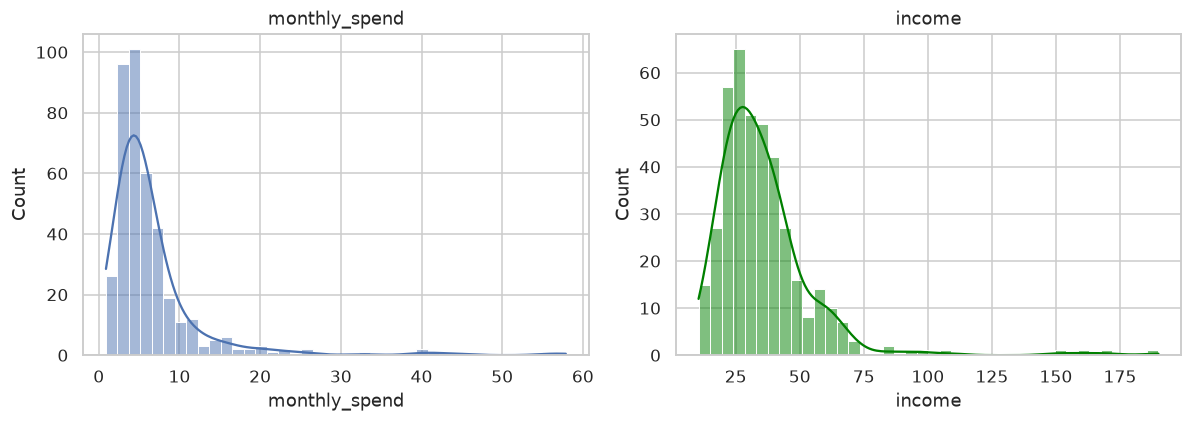

monthly_spend    4.42
income           3.58
dtype: float64
monthly_spend    0.88
income           0.51
dtype: float64


In [769]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df['monthly_spend'], bins=40, kde=True, ax=ax[0])
sns.histplot(df['income'], bins=40, kde=True, ax=ax[1], color='green')
ax[0].set_title('monthly_spend'); ax[1].set_title('income')
plt.tight_layout()
plt.show()

print(df[['monthly_spend', 'income']].skew().round(2))
print(np.log(df[['monthly_spend', 'income']]).skew().round(2))

<div dir="rtl" style="text-align: right;">

هر دو توزیع به راست کشیده اند. چولگی monthly_spend برابر 4.42 و income برابر 3.58 است. بعد از لگاریتم به 0.88 و 0.51 می رسد، پس توی سوال 2 احتمالا Box-Cox لازم می شود.

</div>

<div dir="rtl" style="text-align: right;">

## ب) درآمد و پس انداز

</div>

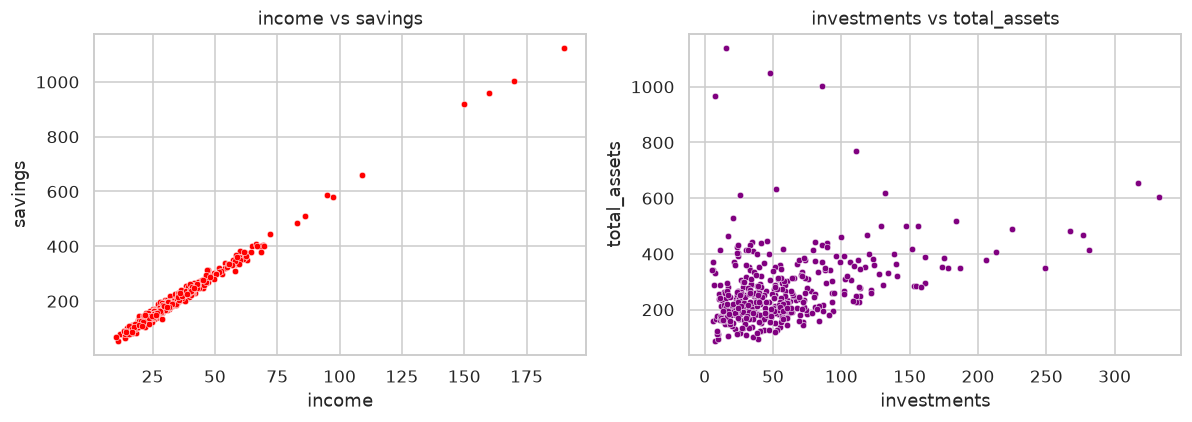

0.9952 0.3768


In [770]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.scatterplot(data=df, x='income', y='savings', ax=ax[0], s=18, color='red')
sns.scatterplot(data=df, x='investments', y='total_assets', ax=ax[1], s=18, color='purple')
ax[0].set_title('income vs savings'); ax[1].set_title('investments vs total_assets')
plt.tight_layout()
plt.show()

print(round(df['income'].corr(df['savings']), 4), round(df['investments'].corr(df['total_assets']), 4))

<div dir="rtl" style="text-align: right;">

نمودار چپ تقریبا خط راست است و همبستگی 0.9952 دارد، یعنی savings تقریبا مضرب ثابتی از income است. total_assets از جمع savings و investments ساخته شده و تنها با investments همبستگی 0.3768 دارد. همین رابطه توی سوال 1-الف مشکل رتبه را می سازد.

</div>

<div dir="rtl" style="text-align: right;">

## ج) خرج در برابر درآمد به تفکیک منطقه

</div>

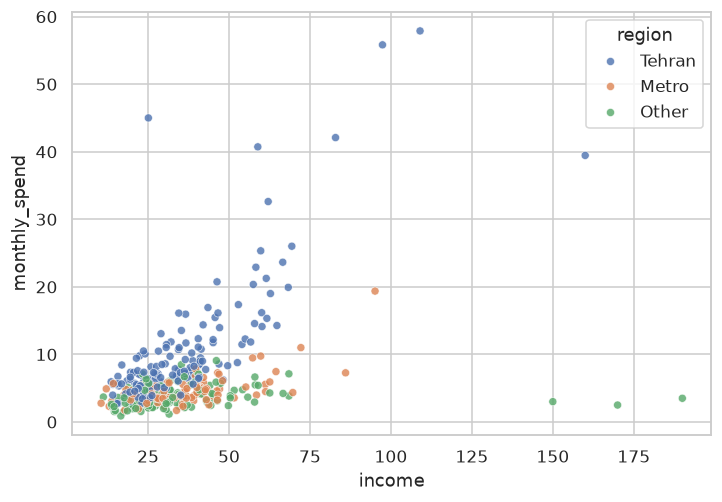

,count,median,mean,std
region,,,,
Tehran,162,7.17,10.10,8.93
Metro,117,4.12,4.54,2.08
Other,121,3.50,3.78,1.61


In [771]:
plt.figure(figsize=(7.5, 5))
sns.scatterplot(data=df, x='income', y='monthly_spend', hue='region', s=28, alpha=0.8)
plt.show()

df.groupby('region', observed=True)['monthly_spend'].agg(['count', 'median', 'mean', 'std']).round(2)

<div dir="rtl" style="text-align: right;">

رابطه مثبت است ولی بیشتر نقطه های پرخرج تهرانی اند. میانه خرج تهران 7.17 و Metro 4.12 و Other 3.50 است. انحراف معیار تهران 8.93 است که حدود 4 برابر Metro با 2.08 و 5.5 برابر Other با 1.61 است. این نشانه ناهمسانی واریانس است و توی سوال 2-الف با Breusch-Pagan چکش می کنم.

</div>

<div dir="rtl" style="text-align: right;">

## د) خرج در هر منطقه

</div>

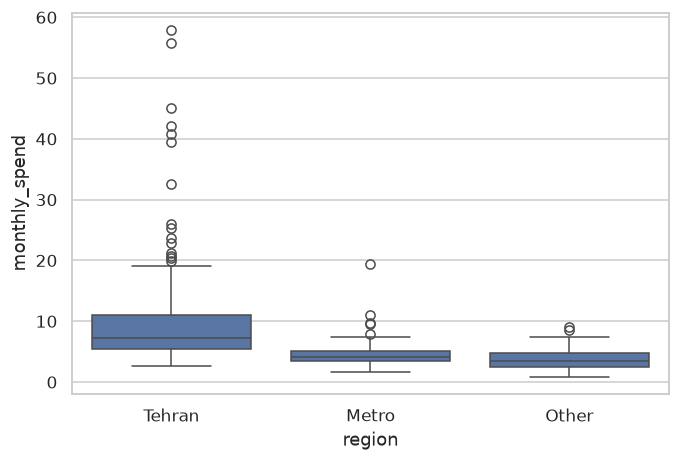

region
Tehran    5.70
Metro     1.61
Other     2.20
Name: monthly_spend, dtype: float64


In [772]:
plt.figure(figsize=(7, 4.5))
sns.boxplot(data=df, x='region', y='monthly_spend', order=['Tehran', 'Metro', 'Other'])
plt.show()
print(df.groupby('region', observed=True)['monthly_spend'].apply(lambda s: s.quantile(0.75) - s.quantile(0.25)).round(2))

<div dir="rtl" style="text-align: right;">

جعبه تهران هم بالاتر است و هم بازتر، فاصله چارکی تهران 5.70 و Metro 1.61 و Other 2.20 است. پنج مقدار بالای خرج تا 57.88 همه تهرانی اند. پس region باید توی مدل باشد.

</div>

<div dir="rtl" style="text-align: right;">

## ه) ماتریس همبستگی

</div>

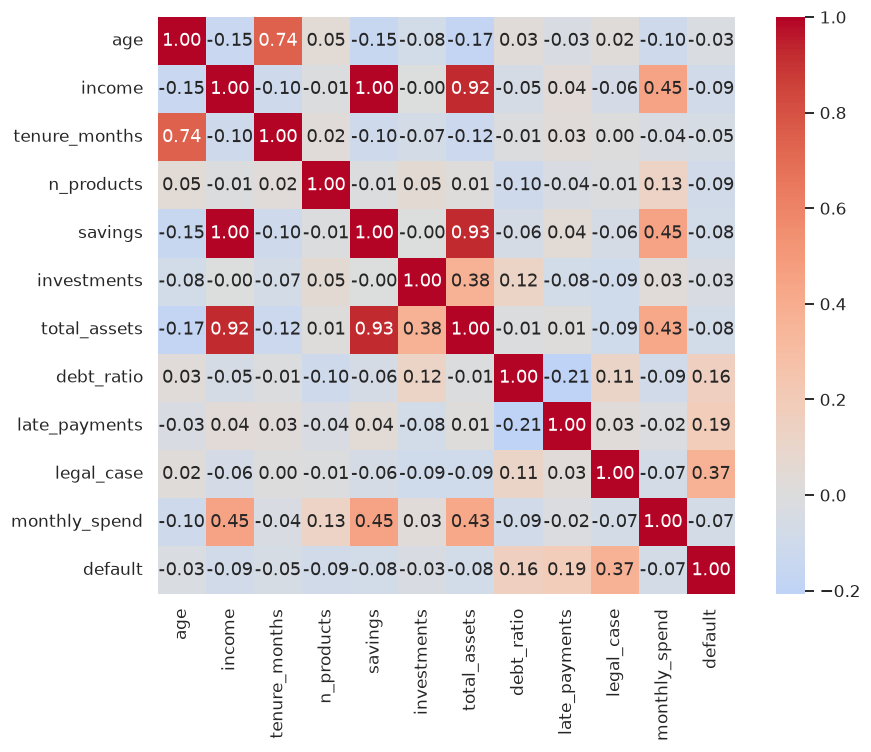

income           0.45
savings          0.45
total_assets     0.43
n_products       0.13
investments      0.03
late_payments   -0.02
tenure_months   -0.04
default         -0.07
legal_case      -0.07
debt_ratio      -0.09
age             -0.10
Name: monthly_spend, dtype: float64


In [773]:
corr = df.select_dtypes('number').drop(columns='id').corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.tight_layout()
plt.show()

print(corr['monthly_spend'].drop('monthly_spend').sort_values(ascending=False).round(2))

<div dir="rtl" style="text-align: right;">

بیشترین همبستگی با monthly_spend مال income و savings است، هر دو 0.45، و بعد total_assets با 0.43. این سه به هم وابسته اند. بقیه مثل age و tenure_months همبستگی خطی ضعیفی دارند، که یعنی رابطه خطی ضعیف است نه این که اثری ندارند.

</div>

<div dir="rtl" style="text-align: right;">

## خلاصه EDA

- monthly_spend و income چولگی راست دارند
- income و savings تقریبا یکی اند و total_assets جمع دو تای دیگر است
- پراکندگی خرج با درآمد زیاد می شود و تهران بیشترین را دارد
- چیزی حذف یا عوض نشد

</div>

<div dir="rtl" style="text-align: right;">

### 9. سوال 1-الف: مدل خام و همخطی کامل

مدل خام را بدون حذف چیزی می زنم، یعنی monthly_spend روی age و income و tenure_months و n_products و savings و investments و total_assets و region.

ماتریس طرح 10 ستون دارد، یعنی عرض از مبدا و 7 متغیر عددی و 2 ستون برای region. اگر همه مستقل باشند رتبه باید 10 شود.

</div>

In [774]:
import statsmodels.formula.api as smf

f_raw = 'monthly_spend ~ age + income + tenure_months + n_products + savings + investments + total_assets + C(region)'
m_raw = smf.ols(f_raw, data=df).fit()
X = m_raw.model.exog
names = m_raw.model.exog_names
n, p = X.shape
print(n, p, np.linalg.matrix_rank(X))

400 10 9


/tmp/ipykernel_11282/759980669.py:4: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m_raw = smf.ols(f_raw, data=df).fit()


<div dir="rtl" style="text-align: right;">

رتبه فقط 9 است، یعنی یک ستون ترکیب خطی بقیه است و ماتریس X'X معکوس پذیر نیست. نرم افزار ولی خطا نمی دهد و عدد می دهد که قابل اعتماد نیستند.

</div>

In [775]:
ev, evec = np.linalg.eigh(X.T @ X)
print( ev[:4] )
print('max ev', ev[-1])
print('cond', np.linalg.cond(X))
print(pd.Series(evec[:, 0], index=names).round(3))

[-1.28451916e-09  1.27895655e+01  5.19900241e+01  1.16607526e+02]
max ev 61827120.977344155
cond 7964366050146438.0
Intercept             0.000
C(region)[T.Metro]   -0.000
C(region)[T.Other]   -0.000
age                  -0.000
income                0.000
tenure_months         0.000
n_products           -0.000
savings              -0.577
investments          -0.577
total_assets          0.577
dtype: float64


<div dir="rtl" style="text-align: right;">

کوچک ترین مقدار ویژه عملا صفر است، حدود 1e-9 و حتی منفی که فقط خطای گرد کردن است. عدد شرط هم از مرتبه 1e15 است و مقدار دقیقش به نسخه کتابخانه و گرد کردن بستگی دارد، پس به رقم دقیقش نگاه نمی کنم. بردار ویژه همین مقدار فقط روی سه ستون عدد دارد، savings و investments و total_assets، هر سه با قدر مطلق 0.577 و علامت total_assets مخالف دو تای دیگر. علامت کلی بردار ویژه قرارداد است و فرقی نمی کند. یعنی total_assets منهای savings منهای investments صفر است، همان چیزی که توی بخش 4 دیدیم.

</div>

In [776]:
pd.DataFrame({'coef': m_raw.params, 'se': m_raw.bse}).round(4)

,coef,se
Intercept,4.6857,1.3661
C(region)[T.Metro],-5.5405,0.6027
C(region)[T.Other],-6.6684,0.5971
age,-0.0734,0.0300
income,0.1777,0.1283
tenure_months,0.0256,0.0127
n_products,0.5916,0.1591
savings,-0.0049,0.0144
investments,0.0050,0.0079
total_assets,0.0001,0.0074


In [777]:
v = evec[:, 0] / evec[:, 0][names.index('total_assets')]
b2 = m_raw.params.values + 5 * v
print('max fitted diff', np.abs(m_raw.fittedvalues.values - X @ b2).max())
for nm in ['savings', 'total_assets']:
    print(nm, round(m_raw.params[nm], 4), round(b2[names.index(nm)], 4))

max fitted diff 1.5972290157151292e-10
savings -0.0049 -5.0049
total_assets 0.0001 5.0001


<div dir="rtl" style="text-align: right;">

وقتی یک جهت صفر داریم می شود هر مقداری از آن جهت را به ضرایب اضافه کرد و مقدارهای برازش شده عوض نمی شوند. اینجا ضرایب را 5 واحد جابه جا کردم، اختلاف برازش ها صفر ماند ولی ضریب savings و total_assets عوض شد. پس ضرایب بی نهایت جواب دارند و فقط پیش بینی ثابت است. اعدادی که نرم افزار چاپ کرده یکی از همین جواب هاست و تفسیر ندارد.

</div>

<div dir="rtl" style="text-align: right;">

## اصلاح مدل

total_assets را حذف می کنم چون دقیقا از savings و investments ساخته می شود و چیزی از دست نمی رود. توی سوال 1-ب می بینیم income و savings هم تقریبا یکی اند، پس savings هم می رود و به مدل بدون total_assets و savings می رسیم که سوال 2 می خواهد.

</div>

In [778]:
f_fix = 'monthly_spend ~ age + income + tenure_months + n_products + savings + investments + C(region)'
m_fix = smf.ols(f_fix, data=df).fit()
Xf = m_fix.model.exog

def info(m, M):
    rk = np.linalg.matrix_rank(M)
    return {'p': M.shape[1], 'rank': rk, 'n-p': n - M.shape[1], 'n-rank': n - rk,
            'min eig': '%.2e' % np.linalg.eigvalsh(M.T @ M)[0],
            'cond': '%.2e' % np.linalg.cond(M),
            'RSS': round(m.ssr, 2), 'R2': round(m.rsquared, 4)}

pd.DataFrame({'raw': info(m_raw, X), 'no total_assets': info(m_fix, Xf)})

,raw,no total_assets
p,10,9
rank,9,9
n-p,390,391
n-rank,391,391
min eig,-1.28e-09,1.28e+01
cond,7.96e+15,1.44e+03
RSS,9555.01,9555.01
R2,0.4408,0.4408


In [779]:
pd.DataFrame({'coef': m_fix.params, 'se': m_fix.bse}).round(4)

,coef,se
Intercept,4.6857,1.3661
C(region)[T.Metro],-5.5405,0.6027
C(region)[T.Other],-6.6684,0.5971
age,-0.0734,0.0300
income,0.1777,0.1283
tenure_months,0.0256,0.0127
n_products,0.5916,0.1591
savings,-0.0047,0.0215
investments,0.0051,0.0052


<div dir="rtl" style="text-align: right;">

## درجه آزادی باقی مانده

قبل از اصلاح، 400 منهای 10 ستون می شود 390 ولی رتبه واقعی 9 است و درجه آزادی درست 391 است. نرم افزار هم 391 می دهد. بعد از اصلاح p و رتبه هر دو 9 است و باز 391 می شود. فرق در تفسیر است، قبلا 10 پارامتر داشتیم و فقط 9 تا قابل برآورد بود.

RSS و R2 هم یکی است، 9555.01 و 0.4408. پس با حذف total_assets پیش بینی بدتر نشد و فقط ضرایب نامعین بودند. عدد شرط هم از حدود e15 به حدود 1.4e3 رسید.

</div>

<div dir="rtl" style="text-align: right;">

### 10. سوال 1-ب: VIF و عدد شرط

همخطی کامل حل شد. حالا می بینم همخطی شدید هم مانده یا نه. مدل مبنا همان بدون total_assets است.

</div>

In [780]:
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif

m_a = m_fix
Xa = m_a.model.exog
na = m_a.model.exog_names
vif_a = pd.Series([vif(Xa, i) for i in range(1, Xa.shape[1])], index=na[1:]).round(2)
vif_a.sort_values(ascending=False).to_frame('VIF')

,VIF
savings,104.42
income,104.27
age,2.27
tenure_months,2.24
C(region)[T.Metro],1.23
C(region)[T.Other],1.23
n_products,1.02
investments,1.01


In [781]:
aux = smf.ols('income ~ age + tenure_months + n_products + savings + investments + C(region)', data=df).fit()
print(round(aux.rsquared, 4), round(1 / (1 - aux.rsquared), 2))

0.9904 104.27


<div dir="rtl" style="text-align: right;">

فقط دو متغیر مشکل دارند، income با VIF برابر 104.27 و savings با 104.42. VIF بالای 10 نگران کننده است و بقیه زیر 2.3 اند. دلیلش این است که R2 رگرسیون income روی بقیه 0.9904 است، یعنی 99 درصد درآمد را بقیه توضیح می دهند که عملا savings است. توی مدل خام VIF بی نهایت می شود.

</div>

In [782]:
def scaled_cond(M):
    Ms = M / np.linalg.norm(M, axis=0)
    s = np.linalg.svd(Ms, compute_uv=False)
    return s[0] / s[-1]

print('raw cond', round(np.linalg.cond(Xa), 1))
print('scaled cond', round(scaled_cond(Xa), 1))

Xs = Xa / np.linalg.norm(Xa, axis=0)
w, V = np.linalg.eigh(Xs.T @ Xs)
print(w[:3].round(5))
print(pd.Series(V[:, 0], index=na).round(3))

raw cond 1438.9
scaled cond 75.5
[0.00113 0.01784 0.07382]
Intercept             0.008
C(region)[T.Metro]    0.001
C(region)[T.Other]   -0.001
age                  -0.006
income                0.707
tenure_months        -0.000
n_products           -0.001
savings              -0.707
investments          -0.001
dtype: float64


<div dir="rtl" style="text-align: right;">

عدد شرط بعد از هم طول کردن ستون ها 75.5 است و بالای حدود 30 یعنی همخطی جدی. عدد بدون مقیاس، 1438.9، تنها قابل قضاوت نیست چون به واحد ستون ها بستگی دارد. کوچک ترین مقدار ویژه حدود 0.0011 است و بردارش تقریبا فقط روی income و savings عدد دارد، با قدر مطلق 0.707 و علامت های مخالف. پس مشکل از همین دو تاست.

</div>

<div dir="rtl" style="text-align: right;">

## راه حل

savings را حذف می کنم و income را نگه می دارم. savings تقریبا 6 برابر income است و چیز جدیدی ندارد و سوال 2 هم همین مدل را می خواهد.

راه های دیگر حذف income به جای savings است که تفسیر را سخت تر می کند، Ridge یا Lasso که هر دو را نگه می دارند ولی ضرایب اریب می شوند و SE و p معمولی از بین می رود، یا ساختن یک نسبت از این دو.

</div>

In [783]:
f_b = 'monthly_spend ~ age + income + tenure_months + n_products + investments + C(region)'
m_b = smf.ols(f_b, data=df).fit()
Xb = m_b.model.exog
vif_b = pd.Series([vif(Xb, i) for i in range(1, Xb.shape[1])], index=m_b.model.exog_names[1:]).round(2)

print('max vif', vif_a.max(), vif_b.max())
print('scaled cond', round(scaled_cond(Xa), 1), round(scaled_cond(Xb), 1))
vif_b.sort_values(ascending=False).to_frame('VIF')

max vif 104.42 2.27
scaled cond 75.5 17.8


,VIF
age,2.27
tenure_months,2.24
C(region)[T.Metro],1.23
C(region)[T.Other],1.23
income,1.02
n_products,1.02
investments,1.01


In [784]:
t1 = pd.DataFrame({'coef': m_a.params, 'se': m_a.bse, 't': m_a.tvalues, 'p': m_a.pvalues})
t2 = pd.DataFrame({'coef': m_b.params, 'se': m_b.bse, 't': m_b.tvalues, 'p': m_b.pvalues})
t1.join(t2, lsuffix='_before', rsuffix='_after').round(4)

,coef_before,se_before,t_before,p_before,coef_after,se_after,t_after,p_after
Intercept,4.6857,1.3661,3.4299,0.0007,4.6674,1.3619,3.4270,0.0007
C(region)[T.Metro],-5.5405,0.6027,-9.1930,0.0000,-5.5449,0.6016,-9.2165,0.0000
C(region)[T.Other],-6.6684,0.5971,-11.1686,0.0000,-6.6663,0.5963,-11.1800,0.0000
age,-0.0734,0.0300,-2.4475,0.0148,-0.0731,0.0299,-2.4439,0.0150
income,0.1777,0.1283,1.3850,0.1668,0.1494,0.0127,11.7794,0.0000
tenure_months,0.0256,0.0127,2.0161,0.0445,0.0256,0.0127,2.0190,0.0442
n_products,0.5916,0.1591,3.7196,0.0002,0.5921,0.1588,3.7275,0.0002
savings,-0.0047,0.0215,-0.2211,0.8251,NaN,NaN,NaN,NaN
investments,0.0051,0.0052,0.9854,0.3250,0.0051,0.0052,0.9893,0.3231


In [785]:
print('income SE', round(m_a.bse['income'], 4), round(m_b.bse['income'], 4), 'ratio', round(m_a.bse['income'] / m_b.bse['income'], 1))
print('income t', round(m_a.tvalues['income'], 2), round(m_b.tvalues['income'], 2))
print('CI before', m_a.conf_int().loc['income'].round(3).tolist())
print('CI after ', m_b.conf_int().loc['income'].round(3).tolist())
print('sqrt vif', round(np.sqrt(vif_a['income']), 2))

income SE 0.1283 0.0127 ratio 10.1
income t 1.39 11.78
CI before [-0.075, 0.43]
CI after  [0.125, 0.174]
sqrt vif 10.21


<div dir="rtl" style="text-align: right;">

بعد از حذف savings، SE ضریب income از 0.1283 به 0.0127 می رسد، حدود 10 برابر کمتر که با ریشه VIF یعنی حدود 10.2 می خورد. قبلا t برابر 1.39 و p برابر 0.167 بود و فاصله اطمینان از منفی 0.075 تا 0.430 می رفت و صفر داخلش بود. حالا t برابر 11.78 و p حدود 1e-27 است. پس با وجود savings نمی شد سهم income را جدا از savings دید. بعد از حذف، income جای هر دو را می گیرد و این t مال ترکیب درآمد و پس انداز است. این هم اثر علّی را ثابت نمی کند و فقط یک رابطه است.

</div>

In [786]:
slope = smf.ols('savings ~ income + age + tenure_months + n_products + investments + C(region)', data=df).fit().params['income']
imp = m_a.params['income'] + slope * m_a.params['savings']
print('slope', round(slope, 3))
print('implied income coef', round(imp, 4), ' after drop', round(m_b.params['income'], 4))
print('max fitted diff', round(np.abs(m_a.fittedvalues - m_b.fittedvalues).max(), 4))
print('R2', round(m_a.rsquared, 4), round(m_b.rsquared, 4))
print('adj R2', round(m_a.rsquared_adj, 4), round(m_b.rsquared_adj, 4))
print('MSE', round(m_a.mse_resid, 3), round(m_b.mse_resid, 3))
print(m_a.f_test('income = 0, savings = 0'))

slope 5.949
implied income coef 0.1494  after drop 0.1494
max fitted diff 0.1713
R2 0.4408 0.4408
adj R2 0.4294 0.4308
MSE 24.437 24.378
<F test: F=69.23354090036518, p=1.819862485850263e-26, df_denom=391, df_num=2>


<div dir="rtl" style="text-align: right;">

## همخطی چه چیزی را خراب می کند

خراب می کند
- SE و t و p متغیرهای همخط، SE درآمد 10 برابر شده بود
- پایداری ضرایب، مثلا ضریب savings منفی 0.0047 بود با SE برابر 0.0215 و p برابر 0.83، یعنی از صفر جدا نمی شد و علامتش هم با همبستگی مثبت 0.45 نمی خواند
- تفسیر تک تک ضرایب

خراب نمی کند
- برازش و پیش بینی، R2 هر دو 0.4408 است و بیشترین اختلاف برازش ها 0.17 که کنار انحراف معیار خرج، حدود 6.5، کوچک است
- MSE هم تقریبا یکی است، 24.44 و 24.38
- ضرایب متغیرهای غیرهمخط مثل age و tenure_months و n_products و investments و region
- آزمون مشترک دو متغیر، F برابر 69.2 و p حدود 1e-26، یعنی با هم معنادارند ولی سهم هرکدام جدا نمی شود

ضریب income بعد از حذف 0.1494 شد که با ضریب income به علاوه شیب savings روی income و بقیه متغیرهای مدل ضرب در ضریب savings قبلی برابر است. این برابری دقیق است و هر دو 0.1494 می شوند. یعنی income اثر savings را هم جذب کرده و حالا نماینده درآمد و ثروت با هم است، پس نباید آن را اثر درآمد با ثابت بودن پس انداز خواند.

</div>

<div dir="rtl" style="text-align: right;">

### 11. سوال 1-ج: ماتریس هت و نقاط تاثیرگذار

مدل همان بدون total_assets و savings است چون توی مدل خام ماتریس X'X معکوس پذیر نیست و سوال 2 هم همین را می خواهد. n برابر 400 و p برابر 8 است.

</div>

In [787]:
m_c = m_b
X = m_c.model.exog
y = df['monthly_spend'].to_numpy()
n, p = X.shape

H = X @ np.linalg.inv(X.T @ X) @ X.T    # hat matrix
h = np.diag(H)

print(n, p)
print('symmetric', np.allclose(H, H.T), ' idempotent', np.allclose(H @ H, H))
print('trace', round(np.trace(H), 6))
print('h range', h.min().round(4), h.max().round(4))

400 8
symmetric True  idempotent True
trace 8.0
h range 0.0075 0.1686


<div dir="rtl" style="text-align: right;">

ماتریس هت را مستقیم با ضرب ماتریس ها ساختم و از تابع آماده استفاده نکردم. متقارن و خودتوان است و ردش 8 است یعنی همان p. میانگین اهرم ها هم p تقسیم بر n یعنی 0.02 است.

</div>

In [788]:
thr = 2 * p / n
hi = h > thr
print('2p/n =', thr, ' count =', hi.sum())
(pd.DataFrame({'id': df['id'], 'h': h, 'income': df['income'], 'region': df['region']})
   .loc[hi].sort_values('h', ascending=False).head(10).round(4))

2p/n = 0.04  count = 16


,id,h,income,region
310,311,0.1686,190.0,Other
367,368,0.1281,170.0,Other
31,32,0.1116,160.0,Tehran
151,152,0.0966,150.0,Other
50,51,0.0907,54.2,Other
160,161,0.0899,47.4,Other
204,205,0.0679,24.7,Tehran
262,263,0.0661,33.1,Metro
325,326,0.0591,36.7,Tehran
150,151,0.0588,43.0,Other


<div dir="rtl" style="text-align: right;">

آستانه دو برابر p تقسیم بر n است که 0.04 می شود و 16 مشاهده از آن بالاترند. چهار تای اول درآمد 150 یا بیشتر دارند، مثل id 311 با درآمد 190. id 51 و 161 با درآمد 54.2 و 47.4 هم اهرم بالا دارند و درآمدشان خیلی بالا نیست.

</div>

In [789]:
e = y - H @ y
sse = e @ e
mse = sse / (n - p)

t_del = e * np.sqrt((n - p - 1) / (sse * (1 - h) - e**2))
cook = e**2 / (p * mse) * h / (1 - h)**2
dff = t_del * np.sqrt(h / (1 - h))

res = pd.DataFrame({'id': df['id'], 'region': df['region'], 'income': df['income'],
                    'spend': df['monthly_spend'], 'h': h, 't_del': t_del, 'cook': cook, 'dffits': dff})

inf = m_c.get_influence()   # only to check
print(np.allclose(h, inf.hat_matrix_diag), np.allclose(cook, inf.cooks_distance[0]),
      np.allclose(dff, inf.dffits[0]), np.allclose(t_del, inf.resid_studentized_external))

True True True True


<div dir="rtl" style="text-align: right;">

همه کمیت ها را با فرمول خودشان حساب کردم و فقط برای اطمینان با کتابخانه مقایسه کردم، هر چهار تا یکی بود. برای Cook فرمول استاندارد را به کار بردم که مخرجش p ضرب در MSE است، نه MSE به توان دو که توی صورت سوال بود.

</div>

In [790]:
res['lev'] = res['h'] > thr
res['out'] = res['t_del'].abs() > 3
res['cook_big'] = res['cook'] > 4 / n
res['dff_big'] = res['dffits'].abs() > 2 * np.sqrt(p / n)
res['infl'] = res['lev'] & res['cook_big']

print('cutoffs: h', thr, ' t 3', ' cook', 4 / n, ' dffits', round(2 * np.sqrt(p / n), 3))
print('leverage', res['lev'].sum(), ' outlier', res['out'].sum(), ' cook>4/n', res['cook_big'].sum(),
      ' dffits', res['dff_big'].sum(), ' influential', res['infl'].sum())
print('max cook', round(res['cook'].max(), 3))
print('lev only', (res['lev'] & ~res['out'] & ~res['infl']).sum(),
      ' out only', (res['out'] & ~res['lev']).sum(),
      ' lev+out', (res['lev'] & res['out']).sum())

cutoffs: h 0.04  t 3  cook 0.01  dffits 0.283
leverage 16  outlier 9  cook>4/n 12  dffits 12  influential 5
max cook 0.656
lev only 11  out only 5  lev+out 4


In [791]:
res.loc[res['lev'] | res['out'] | res['cook_big']].sort_values('cook', ascending=False).head(12).round(3)

,id,region,income,spend,h,t_del,cook,dffits,lev,out,cook_big,dff_big,infl
310,311,Other,190.0,3.50,0.169,-5.255,0.656,-2.367,True,True,True,True,True
367,368,Other,170.0,2.50,0.128,-4.879,0.413,-1.870,True,True,True,True,True
83,84,Tehran,109.0,57.88,0.053,7.724,0.366,1.836,True,True,True,True,True
99,100,Tehran,97.4,55.82,0.032,8.041,0.229,1.458,False,True,True,True,False
151,152,Other,150.0,3.00,0.097,-4.195,0.226,-1.372,True,True,True,True,True
365,366,Tehran,82.9,42.09,0.034,5.516,0.126,1.040,False,True,True,True,False
397,398,Tehran,58.9,40.72,0.035,5.032,0.107,0.954,False,True,True,True,False
31,32,Tehran,160.0,39.45,0.112,2.480,0.095,0.879,True,False,True,True,True
355,356,Tehran,25.1,45.00,0.010,7.801,0.069,0.797,False,True,True,True,False
185,186,Tehran,62.1,32.62,0.024,3.582,0.038,0.559,False,True,True,True,False


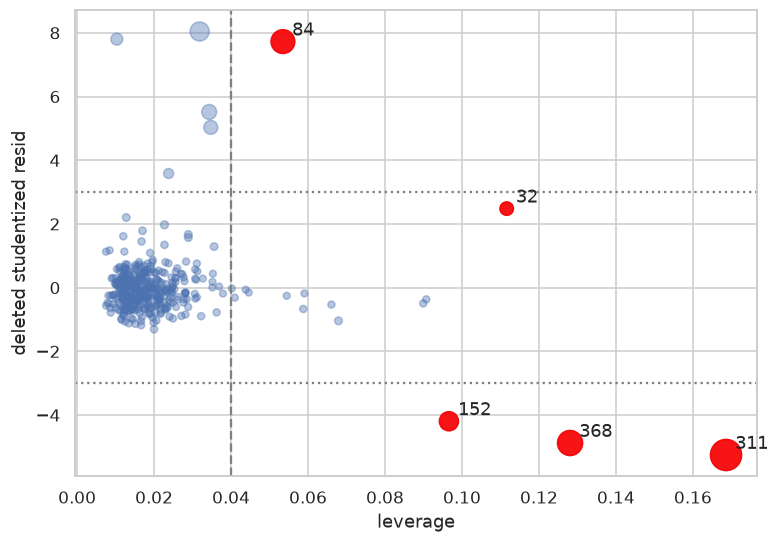

In [792]:
plt.figure(figsize=(8, 5.5))
plt.scatter(res['h'], res['t_del'], s=20 + 600 * res['cook'], alpha=0.4)
ii = res[res['infl']]
plt.scatter(ii['h'], ii['t_del'], s=20 + 600 * ii['cook'], color='red', alpha=0.9)
for _, r in ii.iterrows():
    plt.annotate(int(r['id']), (r['h'], r['t_del']), xytext=(6, 4), textcoords='offset points')
plt.axvline(thr, ls='--', color='gray')
plt.axhline(3, ls=':', color='gray')
plt.axhline(-3, ls=':', color='gray')
plt.xlabel('leverage')
plt.ylabel('deleted studentized resid')
plt.show()

<div dir="rtl" style="text-align: right;">

## دسته بندی

- اهرمی، 16 مشاهده: اهرم بزرگ تر از 0.04
- پرت، 9 مشاهده: قدر مطلق باقی مانده استیودنتی حذفی بزرگ تر از 3. پنج تا فقط پرت اند که id 100 و 366 و 398 و 356 و 186 هستند و همه تهرانی با خرج خیلی بالا اند. چهار تای دیگر اهرمی هم هستند
- تاثیرگذار، 5 مشاهده: هم اهرم بزرگ و هم Cook بزرگ تر از چهار تقسیم بر n. یعنی id 311 و 368 و 84 و 152 و 32

11 مشاهده فقط اهرمی اند و اثر زیادی ندارند چون روی روند بقیه اند.

id 311 و 368 و 152 درآمد خیلی بالا با خرج کم دارند و همه Other اند، پس شیب income را پایین می کشند. id 84 بیشترین خرج کل را دارد، 57.88. id 32 اهرم بالا دارد ولی پرت نیست.

بیشترین Cook برابر 0.656 است و هیچ کدام بالای 1 نیستند. با قاعده سخت گیرانه 1 هیچ نقطه ای مشکل ساز نیست. من چهار تقسیم بر n را گذاشتم که حساس تر است.

</div>

In [793]:
keep = ~res['infl'].to_numpy()
m_drop = smf.ols(f_b, data=df.loc[keep]).fit()

ch = pd.DataFrame({'full': m_c.params, 'drop': m_drop.params, 'se_full': m_c.bse, 'se_drop': m_drop.bse})
ch['pct'] = (ch['drop'] - ch['full']) / ch['full'].abs() * 100
ch['in_se'] = (ch['drop'] - ch['full']) / ch['se_full']
print(len(df), '->', int(m_drop.nobs))
print('R2', round(m_c.rsquared, 4), round(m_drop.rsquared, 4))
print('MSE', round(m_c.mse_resid, 2), round(m_drop.mse_resid, 2))
ch.round(4)

400 -> 395
R2 0.4408 0.5132
MSE 24.38 16.76


,full,drop,se_full,se_drop,pct,in_se
Intercept,4.6674,1.8570,1.3619,1.1896,-60.2124,-2.0635
C(region)[T.Metro],-5.5449,-5.3398,0.6016,0.5003,3.6985,0.3409
C(region)[T.Other],-6.6663,-5.6983,0.5963,0.4998,14.5200,1.6233
age,-0.0731,-0.0613,0.0299,0.0249,16.2115,0.3962
income,0.1494,0.2133,0.0127,0.0148,42.6935,5.0291
tenure_months,0.0256,0.0262,0.0127,0.0105,2.1102,0.0426
n_products,0.5921,0.5774,0.1588,0.1326,-2.4867,-0.0927
investments,0.0051,0.0023,0.0052,0.0043,-55.5435,-0.5495


<div dir="rtl" style="text-align: right;">

## مدل بدون نقاط تاثیرگذار

بعد از حذف 5 مشاهده 395 سطر می ماند. ضریب income از 0.1494 به 0.2133 می رود که حدود 43 درصد بیشتر و حدود 5 برابر SE قبلی است، پس برازش به این پنج نفر حساس است. سه تا از نقطه ها، 311 و 368 و 152، درآمد بالا و خرج کم داشتند و دو تا، 84 و 32، تهرانی پرخرج بودند.

عرض از مبدا از 4.67 به 1.86 می رسد و ضریب Other از منفی 6.67 به منفی 5.70. بقیه کم عوض می شوند. R2 از 0.441 به 0.513 و MSE از 24.38 به 16.76 می رسد.

این تغییر ثابت نمی کند که این پنج نفر اشتباه ثبت شده اند یا باید حذف شوند، پس هر دو مدل را کنار هم گزارش می کنم. توی 1-د توضیح می دهم چرا حذف خودکار درست نیست.

</div>

<div dir="rtl" style="text-align: right;">

### سوال 1-د (مفهومی)

بند i. مقدار برازش هر مشاهده ترکیبی خطی از y هاست و ضریب خود y مشاهده i توی آن همان درایه قطری ماتریس هت است، پس مشتق برابر اهرم است. ماتریس هت متقارن و خودتوان است، برای همین هر درایه قطری برابر جمع مربع های درایه های سطر خودش است. این جمع شامل مربع خود آن درایه و بقیه جمله های نامنفی است، پس اهرم از مربع خودش کمتر نیست و عددی بین صفر و یک می شود.

بند ii. بعد از حذف مشاهده i ماتریس X'X یک ماتریس رتبه یک را از دست می دهد و معکوس جدید با فرمول Sherman-Morrison درمی آید. با جایگذاری، ضرایب به اندازه معکوس X'X ضرب در سطر i و باقی مانده تقسیم بر یک منهای اهرم عوض می شوند. نتیجه این است که پیش بینی مشاهده i بدون خودش با برازش معمولی به اندازه اهرم ضرب در باقی مانده تقسیم بر یک منهای اهرم فرق دارد، پایین تر اگر باقی مانده مثبت باشد و بالاتر اگر منفی باشد، پس باقی مانده حذفی برابر باقی مانده معمولی تقسیم بر یک منهای اهرم است.

بند iii. Cook از دو چیز ساخته می شود، مجذور باقی مانده و نسبت اهرم به مجذور یک منهای اهرم. پس اگر یکی کوچک باشد Cook هم می تواند کوچک بماند. id 51 اهرم بالا دارد، 0.0907، ولی باقی مانده اش کوچک است، منفی 1.74، پس Cook فقط 0.0017 است. id 100 اهرم کم دارد، 0.0318، ولی باقی مانده اش 36.23 است پس Cook برابر 0.229 می شود. توی صورت سوال MSE به توان دو آمده که غلط تایپی است.

بند iv. نه. اهرم بالا یعنی ترکیب پیش بین ها غیرعادی است و به معنی غلط بودن داده یا اثر زیاد نیست. نقطه با اهرم بالا و باقی مانده کوچک، مثل id 51، به دقت برآورد کمک هم می کند. اول باید داده بررسی شود و اگر معتبر بود نگه داشته شود و نتیجه با و بدون آن گزارش شود.

اسکن پاسخ دست نویس این پایین است.

</div>

![اسکن پاسخ دست نویس 1-د، صفحه 1](images/1d_page1.jpg)

![اسکن پاسخ دست نویس 1-د، صفحه 2](images/1d_page2.jpg)

<div dir="rtl" style="text-align: right;">

---

</div>

<div dir="rtl" style="text-align: right;">

### 12. سوال 2-الف: فرضیات مدل

مدل بدون total_assets و savings را روی هر 400 سطر می زنم. واریانس ثابت را با Breusch-Pagan و نمودار باقی مانده چک می کنم و نرمال بودن خطا را با Shapiro-Wilk و Q-Q.

</div>

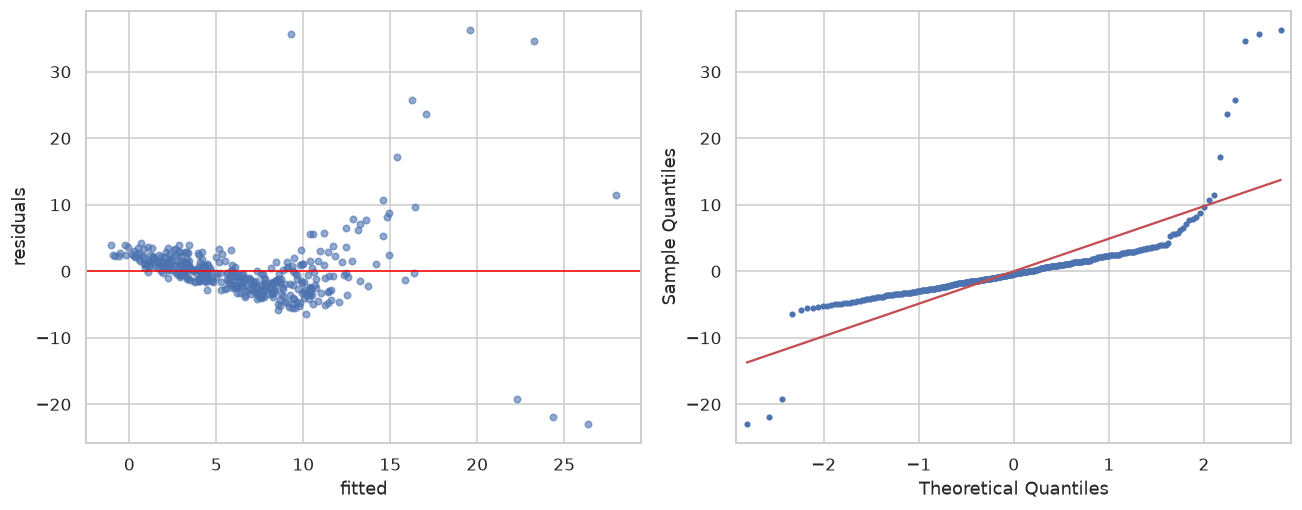

In [794]:
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan

m2 = m_b
X2 = m2.model.exog
r2 = m2.resid
fit2 = m2.fittedvalues

fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
ax[0].scatter(fit2, r2, s=18, alpha=0.6)
ax[0].axhline(0, color='red', lw=1)
ax[0].set_xlabel('fitted')
ax[0].set_ylabel('residuals')
sm.qqplot(r2, line='s', ax=ax[1], markersize=3)
plt.tight_layout()
plt.show()

In [795]:
bp = het_breuschpagan(r2, X2)
sw = stats.shapiro(r2)
print('BP  LM', round(bp[0], 2), ' p', bp[1])
print('SW  W', round(sw[0], 4), ' p', sw[1])
print('skew', round(stats.skew(r2), 2), ' kurt', round(stats.kurtosis(r2), 2))
print('fitted <= 0:', (fit2 <= 0).sum(), ' min', round(fit2.min(), 2))

BP  LM 89.26  p 1.7522192800499403e-16
SW  W 0.6567  p 1.3371131253628155e-27
skew 3.09  kurt 24.86
fitted <= 0: 8  min -1.04


In [796]:
print(pd.DataFrame({'r': r2, 'region': df['region']}).groupby('region', observed=True)['r'].agg(['std', 'min', 'max']).round(2))
q = pd.Series(r2.values).groupby(pd.qcut(fit2.values, 4), observed=True).std().round(2)
q.index = ['Q1', 'Q2', 'Q3', 'Q4']
print(q)
g2 = pd.cut(fit2, [-10, 2, 5, 10, 15, 100])
print(r2.groupby(g2, observed=True).agg(['count', 'mean', 'std']).round(2))
print('RESET p', '%.1e' % sm.OLS(y, np.column_stack([X2, fit2 ** 2])).fit().pvalues[-1])

         std    min    max
region                    
Tehran  6.72  -6.39  36.23
Metro   1.84  -4.73   6.24
Other   3.98 -22.90   3.97
Q1    1.26
Q2    1.51
Q3    4.05
Q4    8.37
dtype: float64
           count  mean    std
(-10, 2]      52  1.93   1.09
(2, 5]       115  0.49   1.43
(5, 10]      155 -1.63   3.52
(10, 15]      66  0.04   4.10
(15, 100]     12  7.76  21.13
RESET p 5.6e-07


<div dir="rtl" style="text-align: right;">

هر دو فرض نقض شده.

ناهمسانی: Breusch-Pagan فرض واریانس ثابت را رد می کند، LM برابر 89.26 و p حدود 1.8e-16. انحراف معیار باقی مانده ها توی چارک های مقدار برازش شده 1.26 و 1.51 و 4.05 و 8.37 است و بر اساس منطقه تهران 6.72 و Other 3.98 و Metro 1.84. یعنی واریانس تقریبا با سطح خرج بالا می رود. انحراف معیار باقی مانده ها توی گروه های مقدار برازش شده، تا 2 و 2 تا 5 و 5 تا 10 و 10 تا 15 و بالای 15، برابر 1.09 و 1.43 و 3.52 و 4.10 و 21.13 است. بیشترین باقی مانده 36.23 و کمترین منفی 22.90 است.

خطی بودن: میانگین باقی مانده ها توی همان پنج گروه مقدار برازش شده 1.93 و 0.49 و منفی 1.63 و 0.04 و 7.76 است، یعنی اول پایین می آید و بعد دوباره بالا می رود. اگر مجذور مقدار برازش شده را به مدل اضافه کنیم هم ضریبش با p حدود 5.6e-7 معنادار است. پس علاوه بر ناهمسانی، خطی بودن هم زیر سوال است.

نرمال نبودن: Shapiro-Wilk فرض نرمال بودن را رد می کند، W برابر 0.657 و p حدود 1e-27. چولگی 3.09 و کشیدگی اضافه 24.86 است، پس توزیع به راست کج است و دنباله سنگین دارد. با چولگی مثبت 3.09 دم راست بلندتر از دم چپ است.

8 مقدار برازش شده هم صفر یا منفی اند و کمترینشان منفی 1.04 است که برای خرج معنی ندارد. همخطی را توی سوال 1 حل کردیم و استقلال خطاها توی داده مقطعی قابل چک نیست.

</div>

<div dir="rtl" style="text-align: right;">

### 13. سوال 2-ب: تبدیل Box-Cox

پاسخ مثبت است و کمترین خرج 0.89 است پس Box-Cox قابل استفاده است. لامبدا را با درست نمایی نیم رخ و با در نظر گرفتن متغیرهای مدل برآورد می کنم نه فقط روی y. فاصله اطمینان 95 درصد همه لامبداهایی است که لگاریتم درست نمایی شان از بیشینه بیشتر از 1.92 پایین نباشد.

</div>

lambda -0.25  CI -0.345 -0.16


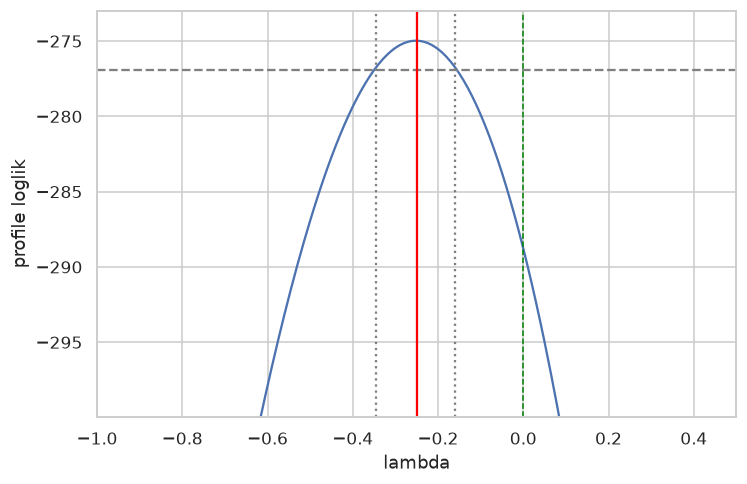

In [797]:
y = df['monthly_spend'].to_numpy()
n = len(y)
sly = np.log(y).sum()

def tr(l):
    return np.log(y) if abs(l) < 1e-9 else (y**l - 1) / l

def pll(l):
    z = tr(l)
    b = np.linalg.lstsq(X2, z, rcond=None)[0]
    rss = ((z - X2 @ b)**2).sum()
    return -n / 2 * np.log(rss / n) + (l - 1) * sly

grid = np.linspace(-1.5, 1.5, 601)
ll = np.array([pll(l) for l in grid])
lam = grid[ll.argmax()]
cut = ll.max() - stats.chi2.ppf(0.95, 1) / 2
ins = grid[ll >= cut]

print('lambda', round(lam, 3), ' CI', round(ins.min(), 3), round(ins.max(), 3))

plt.figure(figsize=(7.5, 4.8))
plt.plot(grid, ll)
plt.axhline(cut, color='gray', ls='--')
plt.axvline(lam, color='red')
plt.axvline(ins.min(), color='gray', ls=':')
plt.axvline(ins.max(), color='gray', ls=':')
plt.axvline(0, color='green', ls='--', lw=1)
plt.xlim(-1, 0.5)
plt.ylim(ll.max() - 25, ll.max() + 2)
plt.xlabel('lambda')
plt.ylabel('profile loglik')
plt.show()

In [798]:
for l in [1, 0.5, 0, -0.25, -0.5]:
    lr = 2 * (ll.max() - pll(l))
    print(l, round(lr, 2), '%.2e' % stats.chi2.sf(lr, 1), lr < 3.84)

1 719.44 1.78e-158 False
0.5 262.4 5.14e-59 False
0 27.6 1.49e-07 False
-0.25 0.0 1.00e+00 True
-0.5 23.9 1.02e-06 False


<div dir="rtl" style="text-align: right;">

لامبدای برآوردی منفی 0.25 است و فاصله اطمینان 95 درصد تقریبا از منفی 0.345 تا منفی 0.16. لامبدا 1 یعنی بدون تبدیل خیلی بیرون است. لگاریتم یعنی لامبدا صفر هم بیرون است، با آماره نسبت درست نمایی 27.6 و p حدود 1.5e-7. توی نمودار خط سبز روی صفر است و زیر خط چین افقی می افتد. منفی 0.25 داخل است.

پس برای بخش ب تبدیل Box-Cox با لامبدای منفی 0.25 را انتخاب می کنم، نه لگاریتم. ولی سوال 2-ج و د مدل لگاریتمی می خواهند، برای همین مدل لگاریتمی را جدا هم می زنم و فقط برای همان محاسبه ها به کار می برم.

تابع boxcox خود scipy فقط روی y کار می کند و منفی 0.36 می دهد. برای رگرسیون همین درست نمایی نیم رخ درست است.

</div>

In [799]:
def diag(z, name):
    b = np.linalg.lstsq(X2, z, rcond=None)[0]
    r = z - X2 @ b
    bp = het_breuschpagan(r, X2)
    sw = stats.shapiro(r)
    return {'model': name, 'BP LM': round(bp[0], 2), 'BP p': '%.1e' % bp[1], 'SW W': round(sw[0], 4),
            'SW p': '%.1e' % sw[1], 'skew': round(stats.skew(r), 2), 'kurt': round(stats.kurtosis(r), 2)}

pd.DataFrame([diag(y, 'y'), diag(tr(lam), 'box-cox'), diag(np.log(y), 'log y')]).set_index('model')

,BP LM,BP p,SW W,SW p,skew,kurt
model,,,,,,
y,89.26,1.8e-16,0.6567,1.3e-27,3.09,24.86
box-cox,94.58,1.4e-17,0.9605,6.7e-09,-0.73,3.04
log y,124.31,9.7e-24,0.9520,4.0e-10,-0.40,4.17


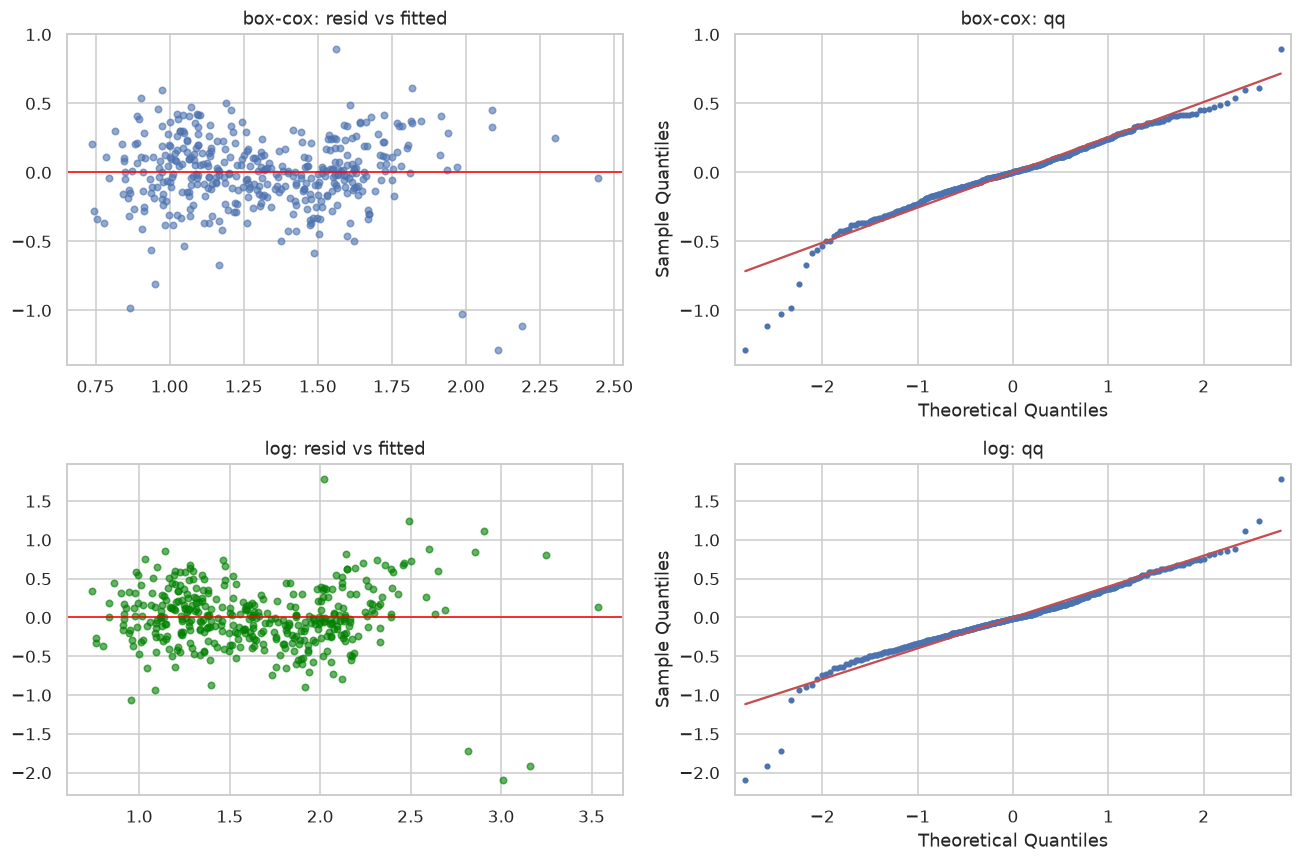

Tehran    0.234
Metro     0.197
Other     0.325
dtype: float64
Tehran    0.417
Metro     0.280
Other     0.468
dtype: float64
[368 311 152] SW all 0.952 SW drop3 0.984 2.5e-04


In [800]:
df['y_bc'] = tr(lam)
m_bc = smf.ols(f_b.replace('monthly_spend', 'y_bc'), data=df).fit()
m_log = smf.ols(f_b.replace('monthly_spend', 'np.log(monthly_spend)'), data=df).fit()
r_bc, f_bc = m_bc.resid, m_bc.fittedvalues
r_log, f_log = m_log.resid, m_log.fittedvalues

fig, ax = plt.subplots(2, 2, figsize=(12, 8))
ax[0, 0].scatter(f_bc, r_bc, s=18, alpha=0.6)
ax[0, 0].axhline(0, color='red', lw=1)
ax[0, 0].set_title('box-cox: resid vs fitted')
sm.qqplot(r_bc, line='s', ax=ax[0, 1], markersize=3)
ax[0, 1].set_title('box-cox: qq')
ax[1, 0].scatter(f_log, r_log, s=18, alpha=0.6, color='green')
ax[1, 0].axhline(0, color='red', lw=1)
ax[1, 0].set_title('log: resid vs fitted')
sm.qqplot(r_log, line='s', ax=ax[1, 1], markersize=3)
ax[1, 1].set_title('log: qq')
plt.tight_layout()
plt.show()

print(pd.Series(r_bc.values).groupby(df['region'].values).std().round(3))
print(pd.Series(r_log.values).groupby(df['region'].values).std().round(3))
ids = df['id'].to_numpy()[np.argsort(r_log.to_numpy())[:3]]
k3 = ~df['id'].isin(ids).to_numpy()
print(ids, 'SW all', round(stats.shapiro(r_log)[0], 3), 'SW drop3', round(stats.shapiro(r_log[k3])[0], 3), '%.1e' % stats.shapiro(r_log[k3])[1])

<div dir="rtl" style="text-align: right;">

مقایسه تشخیص ها، به ترتیب LM آزمون Breusch-Pagan و W آزمون Shapiro-Wilk و چولگی
- y اصلی: 89.26 و 0.657 و 3.09
- Box-Cox با لامبدای منفی 0.25: 94.58 و 0.9605 و منفی 0.73
- لگاریتم: 124.31 و 0.952 و منفی 0.40

چولگی خیلی کمتر شد و W از 0.657 به 0.9605 رسید، ولی Shapiro-Wilk هنوز فرض نرمال بودن را رد می کند با p حدود 6.7e-9. Breusch-Pagan هم هنوز فرض واریانس ثابت را رد می کند با p حدود 1.4e-17 و LM از 89.26 به 94.58 رفته، یعنی ناهمسانی با Box-Cox بهتر نشد. پس نرمال بودن بهتر شد ولی واریانس ثابت نشد. انحراف معیار باقی مانده ها بین منطقه ها هنوز فرق دارد، Tehran 0.234 و Metro 0.197 و Other 0.325.

توی مدل لگاریتمی انحراف معیار باقی مانده ها 0.417 و 0.280 و 0.468 است و LM برابر 124.31 است که از Box-Cox بدتر است. سه کوچک ترین باقی مانده مال id 368 و 311 و 152 هستند، همان مشتری های Other با درآمد بالا و خرج کم. بدون این سه نفر W از 0.952 به 0.984 می رسد ولی Shapiro-Wilk باز هم رد می کند، با p حدود 2.5e-4. پس این سه نفر بخشی از مشکل اند نه همه اش.

لگاریتم هم در Breusch-Pagan و هم در W بدتر از Box-Cox است ولی جهت هر 8 ضریب یکی است. برای همین توی ج و د که سوال لگاریتم می خواهد از آن استفاده می کنم. شکل نمودارها را اینجا از روی عدد ثابت نکردم و نتیجه ها فقط روی عددهای بالا است.

</div>

In [801]:
cb = m_bc.conf_int().loc['income']
print('box-cox income coef', round(m_bc.params['income'], 6), ' CI', cb.round(6).tolist())
print('log income coef', round(m_log.params['income'], 6), ' pct', round((np.exp(m_log.params['income']) - 1) * 100, 2))
print('same coef signs:', bool((np.sign(m_bc.params) == np.sign(m_log.params)).all()))
print('R2 box-cox', round(m_bc.rsquared, 4), ' log', round(m_log.rsquared, 4))

box-cox income coef 0.007526  CI [0.006225, 0.008827]
log income coef 0.012684  pct 1.28
same coef signs: True
R2 box-cox 0.5817  log 0.5893


<div dir="rtl" style="text-align: right;">

تفسیر income توی مدل Box-Cox: هر یک میلیون تومان درآمد بیشتر، با ثابت بودن بقیه، پاسخ تبدیل شده را 0.0075 بیشتر می کند و فاصله اطمینان آن 0.0062 تا 0.0088 است. این روی مقیاس لامبدای منفی 0.25 است و تغییر درصدی ثابتی روی خرج اصلی نیست.

توی مدل لگاریتمی ضریب income برابر 0.0127 است، یعنی هر یک میلیون تومان درآمد بیشتر خرج را حدود 1.28 درصد بیشتر می کند. این تفسیر مال مدل لگاریتمی است و جای تفسیر Box-Cox را نمی گیرد.

</div>

<div dir="rtl" style="text-align: right;">

### 14. سوال 2-ج: WLS و رگرسیون مقاوم

## تابع واریانس

چند تابع واریانس را امتحان می کنم و بعد از وزن دهی دوباره Breusch-Pagan را روی باقی مانده های وزنی می زنم. هدف این است که واریانس تقریبا ثابت شود.

</div>

In [802]:
sq = r2 ** 2

def wchk(w, name):
    fw = sm.WLS(y, X2, weights=w).fit()
    lm, p, _, _ = het_breuschpagan(fw.resid * np.sqrt(w), X2)
    return {'var function': name, 'BP LM': round(lm, 1), 'BP p': '%.1e' % p}

w_reg = 1 / sq.groupby(df['region'], observed=True).transform('mean').to_numpy()

aux = smf.ols('np.log(sq) ~ C(region) + np.log(income)', data=df.assign(sq=sq)).fit()
w_aux = 1 / np.exp(aux.fittedvalues.to_numpy())

w_f2 = 1 / np.maximum(fit2.to_numpy(), 1.0) ** 2

pd.DataFrame([wchk(np.ones(n), 'none'), wchk(w_reg, 'region'), wchk(w_aux, 'region + log income'),
              wchk(w_f2, 'fitted^2')]).set_index('var function')

,BP LM,BP p
var function,,
none,89.3,1.8e-16
region,102.3,3.6e-19
region + log income,19.8,6.1e-03
fitted^2,6.0,5.4e-01


<div dir="rtl" style="text-align: right;">

تابع انتخابی واریانس متناسب با مجذور مقدار برازش شده است، یعنی وزن هر مشاهده یک بر مجذور مقدار برازش شده اش. یعنی انحراف معیار خطا با میانگین متناسب است که برای خرج منطقی است. فقط همین تابع بعد از وزن دهی فرض واریانس ثابت را در Breusch-Pagan رد نمی کند، با LM برابر 6 و p حدود 0.54. این هم اثبات همسانی نیست و فقط شواهدی برای رد کردنش نداریم. وزن بر اساس منطقه با p حدود 1e-19 و بر اساس منطقه و لگاریتم درآمد با p حدود 0.006 هنوز ناهمسانی دارند.

24 مقدار برازش شده کمتر از 1 هستند و 8 تا از آن ها صفر یا منفی اند. برای این که وزن بی نهایت نشود آن ها را از پایین به 1 بریدم. این یک قرارداد است و حساسیت نتیجه به آن را توی مقایسه برآوردگرها چک کرده ام. انتخاب تابع هم با همین آزمون روی همان داده انجام شده.

</div>

In [803]:
ols = sm.OLS(y, X2).fit()
ols3 = ols.get_robustcov_results('HC3')
wls = sm.WLS(y, X2, weights=w_f2).fit()
hub = sm.RLM(y, X2, M=sm.robust.norms.HuberT()).fit()
tuk = sm.RLM(y, X2, M=sm.robust.norms.TukeyBiweight()).fit()

nm = m2.model.exog_names
print(pd.DataFrame({'OLS': ols.params, 'WLS': wls.params, 'Huber': hub.params, 'Tukey': tuk.params}, index=nm).round(4))
print()
print(pd.DataFrame({'OLS': ols.bse, 'OLS HC3': ols3.bse, 'WLS': wls.bse, 'Huber': hub.bse, 'Tukey': tuk.bse}, index=nm).round(4))

                       OLS     WLS   Huber   Tukey
Intercept           4.6674  5.2033  3.6059  3.6504
C(region)[T.Metro] -5.5449 -3.3663 -3.6926 -2.8726
C(region)[T.Other] -6.6663 -4.0958 -4.2526 -3.4244
age                -0.0731 -0.0250 -0.0377 -0.0251
income              0.1494  0.0770  0.1149  0.0828
tenure_months       0.0256  0.0107  0.0171  0.0131
n_products          0.5921  0.3352  0.4513  0.4033
investments         0.0051 -0.0043 -0.0011 -0.0016

                       OLS  OLS HC3     WLS   Huber   Tukey
Intercept           1.3619   2.0426  0.5514  0.5690  0.4690
C(region)[T.Metro]  0.6016   0.5633  0.3996  0.2513  0.2072
C(region)[T.Other]  0.5963   0.7116  0.3867  0.2491  0.2053
age                 0.0299   0.0228  0.0076  0.0125  0.0103
income              0.0127   0.0476  0.0084  0.0053  0.0044
tenure_months       0.0127   0.0092  0.0036  0.0053  0.0044
n_products          0.1588   0.1938  0.0580  0.0664  0.0547
investments         0.0052   0.0046  0.0020  0.0022  0.0018


In [804]:
ii = nm.index('income')
big = ols.resid > 10
rich = (df['income'].to_numpy() > 140) & (df['region'].to_numpy() == 'Other')
print(big.sum(), 'obs with resid > 10 ->', round(sm.OLS(y[~big], X2[~big]).fit().params[ii], 4))
print(rich.sum(), 'Other obs with income > 140 ->', round(sm.OLS(y[~rich], X2[~rich]).fit().params[ii], 4))
for fl in [0.5, 1, 2]:
    w = 1 / np.maximum(fit2.to_numpy(), fl) ** 2
    fw = sm.WLS(y, X2, weights=w).fit()
    print('floor', fl, 'income', round(fw.params[ii], 4), 'BP p', round(het_breuschpagan(fw.resid * np.sqrt(w), X2)[1], 3))
ji = nm.index('investments')
print('max |coef| * sd investments', round(max(abs(m.params[ji]) for m in [ols, wls, hub, tuk]) * df['investments'].std(), 2), ' sd spend', round(y.std(), 2))

8 obs with resid > 10 -> 0.0797
3 Other obs with income > 140 -> 0.2404
floor 0.5 income 0.0635 BP p 0.551
floor 1 income 0.077 BP p 0.539
floor 2 income 0.0867 BP p 0.155
max |coef| * sd investments 0.25  sd spend 6.54


<div dir="rtl" style="text-align: right;">

## مقایسه برآوردگرها روی مقیاس اصلی

ضریب income با هر روش، مقدار و بعد SE
- OLS: 0.1494 و 0.0127
- OLS با HC3: 0.1494 و 0.0476
- WLS: 0.0770 و 0.0084
- Huber: 0.1149 و 0.0053
- Tukey: 0.0828 و 0.0044

SE ساده OLS برای income کم برآورد شده و HC3 حدود 3.7 برابر آن است. ضریب OLS اریب نیست ولی SE و آزمون هایش قابل اعتماد نیستند. با HC3 هنوز income معنادار است و t حدود 3.1 می شود.

با روش های مقاوم ضریب income کوچک تر می شود. دلیلش تهرانی های پرخرجی است که شیب OLS را بالا می کشیدند، چون بدون هشت مشاهده با باقی مانده بالای 10 ضریب OLS از 0.149 به 0.080 می رسد. برعکس، سه مشتری Other با درآمد بالای 140 شیب را پایین می کشند و بدون آن ها ضریب 0.240 می شود. Huber وزن ها را فقط کم می کند و صفر نمی کند برای همین بین OLS و Tukey است. ضریب region هم کوچک تر می شود، مثلا Other از منفی 6.67 در OLS به منفی 3.42 در Tukey. investments هم توی همه روش ها اثر عملی ندارد، چون ضریبش ضرب در انحراف معیار investments حداکثر 0.25 می شود که کنار انحراف معیار خرج، 6.54، کوچک است.

حساسیت WLS به کف مقدار برازش شده: با کف 0.5 و 1 و 2 ضریب income برابر 0.0635 و 0.0770 و 0.0867 می شود و p آزمون Breusch-Pagan برابر 0.551 و 0.539 و 0.155. پس جهت نتیجه عوض نمی شود و رد نشدن همسانی هم سر جایش می ماند، ولی عدد ضریب کمی با کف جابه جا می شود.

SE های Huber و Tukey از خود مدل مقاوم می آیند و با HC3 مستقیم قابل مقایسه نیستند. SE معمولی WLS هم وزن ها را معلوم فرض می کند در حالی که از داده برآورد شده اند، برای استنباط دقیق تر کوواریانس مقاوم یا بوت استرپ بهتر است. این ضریب ها فقط رابطه را نشان می دهند و اثر علّی نیستند.

</div>

In [805]:
tw = pd.DataFrame({'id': df['id'], 'region': df['region'], 'income': df['income'], 'spend': df['monthly_spend'],
                   'ols_resid': ols.resid.round(1), 'w_tukey': tuk.weights.round(3)})
print('w=0:', (tuk.weights == 0).sum(), ' w<0.5:', (tuk.weights < 0.5).sum())
print(tw.groupby('region', observed=True)['w_tukey'].mean().round(3))
rs = (y - X2 @ tuk.params) / tuk.scale
print('w=0 by region:', tw.loc[tuk.weights == 0, 'region'].value_counts().to_dict())
print('id 66 resid / scale:', round(rs[(df['id'] == 66).to_numpy()][0], 2), ' cut 4.685')
tw[tw['id'].isin([32, 66, 152, 186, 311, 356, 398])]

w=0: 25  w<0.5: 41
region
Tehran    0.723
Metro     0.940
Other     0.905
Name: w_tukey, dtype: float64
w=0 by region: {'Tehran': 21, 'Other': 3, 'Metro': 1}
id 66 resid / scale: 4.72  cut 4.685


,id,region,income,spend,ols_resid,w_tukey
31,32,Tehran,160.0,39.45,11.5,0.0
65,66,Tehran,52.9,17.36,2.4,0.0
151,152,Other,150.0,3.00,-19.3,0.0
185,186,Tehran,62.1,32.62,17.2,0.0
310,311,Other,190.0,3.50,-22.9,0.0
355,356,Tehran,25.1,45.00,35.7,0.0
397,398,Tehran,58.9,40.72,23.7,0.0


<div dir="rtl" style="text-align: right;">

## وزن های Tukey

25 مشاهده وزن صفر می گیرند و 41 مشاهده وزن کمتر از 0.5. این ها مشاهده های پرت از نظر باقی مانده اند نه لزوما اهرمی. باقی مانده نسبت به برازش خود Tukey سنجیده می شود نه OLS، برای همین مثلا id 66 با باقی مانده کوچک OLS، یعنی 2.4، هم وزن صفر دارد، چون باقی مانده اش نسبت به برازش Tukey تقسیم بر مقیاس آن 4.72 است که از برش 4.685 بیشتر است.

از 25 مشاهده با وزن صفر، 21 تا تهرانی اند، 3 تا Other و 1 تا Metro. تهرانی های پرخرج مثل id 398 و 356 و 186 با باقی مانده OLS مثبت 17 تا 36، و چند مشتری Other با درآمد خیلی بالا و خرج کم، یعنی id 152 و 311 با باقی مانده منفی 19 و منفی 23. میانگین وزن توی تهران 0.72 است و Other 0.91 و Metro 0.94 که با ناهمسانی بخش الف می خورد.

Cook و Tukey یکی نیستند. Cook نقطه هایی را پیدا می کند که برازش را جابه جا می کنند و Tukey نقطه هایی را که با الگوی اکثریت نمی خوانند. مثلا id 32 هم اهرم بالا دارد و هم وزن Tukey اش صفر است.

</div>

<div dir="rtl" style="text-align: right;">

## پیش بینی برای مشتری جدید، مدل لگاریتمی

سن 40، درآمد 35، 60 ماه سابقه، 3 محصول، سرمایه گذاری 40 و منطقه تهران.

</div>

In [806]:
x0 = pd.DataFrame({'age': [40], 'income': [35], 'tenure_months': [60], 'n_products': [3], 'investments': [40],
                   'region': pd.Categorical(['Tehran'], categories=['Tehran', 'Metro', 'Other'])})

pr = m_log.get_prediction(x0).summary_frame(alpha=0.05)
print(pr.round(4).to_string(index=False))
bk = np.exp(pr[['mean', 'mean_ci_lower', 'mean_ci_upper', 'obs_ci_lower', 'obs_ci_upper']])
print(bk.round(2).to_string(index=False))

eta = pr['mean'].iloc[0]
s2 = m_log.mse_resid
med = np.exp(eta)
nrm = np.exp(eta + s2 / 2)
# delta method ci for the mean: var(log mean) ~ se(eta)^2 + s2^2 / (2 df)
se_lm = np.sqrt(pr['mean_se'].iloc[0]**2 + s2**2 / (2 * m_log.df_resid))
ci_m = np.exp(np.log(nrm) + np.array([-1.96, 1.96]) * se_lm)

er = np.exp(m_log.resid)
smear = er.mean()
smear_teh = er.groupby(df['region'], observed=True).mean()['Tehran']

print('median', round(med, 2))
print('normal corr', round(nrm, 2), ' ci', ci_m.round(2))
print('duan', round(med * smear, 2), ' tehran duan', round(med * smear_teh, 2), round(smear_teh, 4))

xv = np.array([{'Intercept': 1, 'C(region)[T.Metro]': 0, 'C(region)[T.Other]': 0, 'age': 40, 'income': 35,
                'tenure_months': 60, 'n_products': 3, 'investments': 40}[k] for k in m_log.model.exog_names])
print('h0', round(xv @ np.linalg.inv(X2.T @ X2) @ xv, 4))

  mean  mean_se  mean_ci_lower  mean_ci_upper  obs_ci_lower  obs_ci_upper
2.1333   0.0432         2.0484         2.2182        1.3385        2.9281
 mean  mean_ci_lower  mean_ci_upper  obs_ci_lower  obs_ci_upper
 8.44           7.76           9.19          3.81         18.69
median 8.44
normal corr 9.15  ci [8.4  9.97]
duan 9.13  tehran duan 9.32 1.1036
h0 0.0115


<div dir="rtl" style="text-align: right;">

روی مقیاس لگاریتمی میانگین پیش بینی 2.1333 است با SE برابر 0.0432. فاصله اطمینان 95 درصد برای میانگین 2.0484 تا 2.2182 و فاصله پیش بینی برای یک مشاهده جدید 1.3385 تا 2.9281 است.

بعد از exp و روی مقیاس اصلی به میلیون تومان
- برآورد نقطه ای 8.44، که میانه است
- فاصله اطمینان 7.76 تا 9.19، که برای میانه است
- فاصله پیش بینی 3.81 تا 18.69

فاصله 7.76 تا 9.19 را نباید فاصله اطمینان میانگین حسابی خواند. برای میانگین حسابی تصحیح نرمال 9.15 می دهد با فاصله اطمینان تقریبی دلتا از 8.40 تا 9.97. Duan سراسری 9.13 می دهد و چون پراکندگی بین منطقه ها فرق دارد ضریب مخصوص تهران را هم حساب کردم که 9.32 می شود، با ضریب 1.1036.

این فاصله ها فرض می کنند واریانس توی مقیاس لگاریتمی ثابت است، ولی Breusch-Pagan هنوز همسانی را رد می کرد، پس فاصله ها فقط تقریب اند. اهرم این مشتری 0.0115 است و زیر 0.04، پس برون یابی نیست.

</div>

In [807]:
fy = np.exp(m_log.fittedvalues)
print('mean y', round(y.mean(), 3))
print('naive', round(fy.mean(), 3))
print('normal', round((fy * np.exp(s2 / 2)).mean(), 3))
print('duan', round((fy * smear).mean(), 3))
print('s2', round(s2, 4), ' exp(s2/2)', round(np.exp(s2 / 2), 4), ' smear', round(smear, 4))

mean y 6.564
naive 5.851
normal 6.344
duan 6.33
s2 0.1616  exp(s2/2) 1.0841  smear 1.0819


<div dir="rtl" style="text-align: right;">

### سوال 2-د (مفهومی)

## i) OLS تحت ناهمسانی

اگر میانگین شرطی خطا صفر و ماتریس طرح رتبه کامل باشد، OLS نااریب می ماند و به برابر بودن واریانس ها نیازی نیست. سازگاری هم برقرار است ولی به شرط های معمولی نمونه گیری هم نیاز دارد، مثل قانون اعداد بزرگ و کراندار بودن واریانس ها. فقط میانگین صفر برای سازگاری کافی نیست.

چیزی که خراب می شود کارایی و SE است. OLS دیگر بهترین برآوردگر خطی نااریب نیست و فرمول معمول SE و t و p غلط می شوند. مثلا SE درآمد 0.0127 بود ولی با HC3 شد 0.0476.

## ii) ساندویچی و BLUE بودن WLS

خطای برآورد OLS برابر ضرب معکوس X'X در X' و خطاهاست. پس واریانسش از سه تکه ساخته می شود، معکوس X'X از دو طرف و وسطش X' ضرب ماتریس واریانس خطاها ضرب X. به این شکل ساندویچی می گویند. اگر واریانس ها برابر باشند وسطش ساده می شود و به فرمول معمول OLS می رسیم. توی عمل ماتریس واریانس خطاها را با مجذور باقی مانده ها جایگزین می کنند، که HC0 است، و HC3 اهرم را هم اصلاح می کند.

WLS همان OLS است روی داده ای که هر مشاهده در ریشه وزنش ضرب شده. اگر وزن هر مشاهده معکوس واریانس خطایش باشد، یعنی وزن ها متناسب با معکوس ماتریس واریانس خطاها، خطاهای جدید واریانس برابر و ناهمبسته می شوند و قضیه گاوس مارکف برقرار است، پس WLS بهترین برآوردگر خطی نااریب است. اگر وزن ها معلوم ولی غلط باشند هنوز نااریب است ولی کارا نیست. اگر وزن ها از همان داده برآورد شوند، SE معمول WLS عدم قطعیت برآورد وزن ها را نادیده می گیرد و BLUE بودنش دقیق نیست.

## iii) مدل لگاریتمی

لگاریتم صعودی است و میانه را حفظ می کند. اگر میانه شرطی خطا صفر باشد، مثلا خطای متقارن حول صفر، نمای پیش بینی خطی برآورد میانه y است. میانگین حسابی ولی برابر میانه ضرب در میانگین نمای خطاست و اگر خطا نرمال باشد این ضریب برابر e به توان نصف واریانس خطا می شود که از یک بزرگ تر است، به خاطر نابرابری ینسن. پس نمای پیش بینی خطی میانگین را کم برآورد می کند. اگر واریانس به x بستگی داشته باشد باید واریانس همان نقطه به کار برود، نه یک واریانس سراسری.

تصحیح نرمال یعنی ضرب در همان ضریب. اینجا واریانس خطا 0.1616 و ضریب 1.084 است. تصحیح Duan یعنی ضرب در میانگین نمای باقی مانده ها که اینجا 1.082 است و نرمال بودن نمی خواهد. ولی یک ضریب سراسری وقتی درست است که میانگین شرطی نمای خطا توی نقطه های پیش بینی تقریبا ثابت باشد و فقط واریانس ثابت بودن کافی نیست.

برای مشتری جدید پیش بینی ساده 8.44 است، نرمال 9.15، Duan 9.13 و Duan مخصوص تهران 9.32. روی کل داده میانگین پیش بینی ساده 5.85 بود و میانگین واقعی 6.56، بعد از تصحیح نرمال و Duan شد 6.34 و 6.33 که هنوز حدود 0.2 کمتر از 6.56 است. این کالیبراسیون روی همان داده است و تضمینی برای بیرون از نمونه نیست.

توی داده ما انحراف معیار باقی مانده لگاریتمی بین منطقه ها فرق دارد، Tehran 0.417 و Metro 0.280 و Other 0.468، پس ضریب سراسری فقط تقریب است و ضریب جدا برای هر منطقه مناسب تر است.

</div>